In [560]:
# Python imports:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.linear_model import LinearRegression




## 2. Empirical Study: KNN for the Iris Data

In [561]:
# Setting up the dataframe for the iris dataset
iris = pd.read_csv("CSV_Files/iris.csv", names=["sepal.length","sepal.width","petal.length","petal.width","variety"], header=0)

# Randomly split the observations into a development set and a final test set, each of roughly the same size. 
# Use train test split with test size=0.5, random state=3373, and class stratification.
iris_dev, iris_test = train_test_split(
    iris,
    test_size=0.5,
    random_state=3373,
    stratify=iris["variety"]
)


#### (a) Using only the development data, use five-fold stratified cross-validation to compare standardized KNN classifiers for k ∈ {1, 2, . . . , 15}. Shuffle the folds and use random_state=3373. Plot the mean cross-validation misclassification error against k.

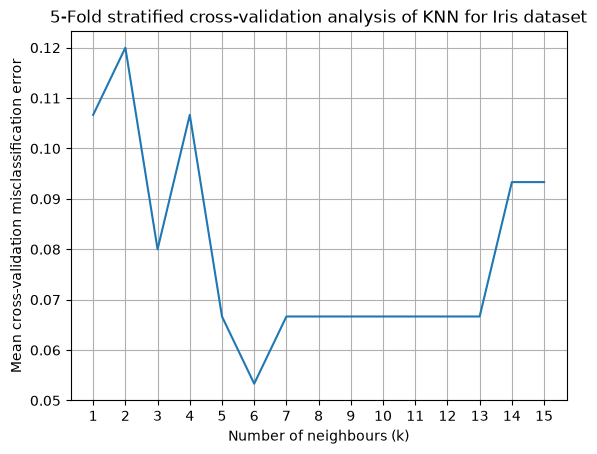

In [562]:
X_dev = iris_dev.drop(columns=["variety"]) # predictor variables (everything but variety)
y_dev = iris_dev["variety"] # target variable (variety)

# setting up stratified cross-validation object
cv = StratifiedKFold(
    n_splits=5, # five folds
    shuffle=True,  # shuffle the folds
    random_state=3373 # fixed random state
)

# list to store mean cross-validation misclassification errors against k
cv_errors = []

# test k-values from 1 to 15 
k_values = range(1, 16) 

# For each k...
for k in k_values:
    # initialize the KNN classifier object for size k WITH STANDARDIZATION (I forgot this and had to redo it)
    knn = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    # Calculate cross-validation accuracy for each fold using sklearn's cross_val_score()
    scores = cross_val_score(
        knn, # knn classifier for given k
        X_dev, # predictor variables from dev data
        y_dev, # target variables from dev data
        cv=cv, # cross-validation model
    )

    # convert accuracies to misclassification errors
    mean_error = np.mean(1 - scores)
    
    # print("k =",k," mean misclassification is: ", mean_error)
    
    # append mean cross-validation misclassification error for size k to errors list
    cv_errors.append(mean_error) 

# plotting the results
plt.plot(k_values, cv_errors) # errors vs k-values
plt.xlabel("Number of neighbours (k)")
plt.ylabel("Mean cross-validation misclassification error")
plt.title("5-Fold stratified cross-validation analysis of KNN for Iris dataset")
plt.xticks(k_values)
plt.grid(True)


#### (b) Select k using the cross-validation results. Refit this classifier using all of the development data, then report its final test error and confusion matrix.

k=6 is clearly the optimal choice suggested by cross-validation, so it is what I will choose. 

In [563]:
k = 6 # my choice of k based on the cross-validation results

X_test = iris_test.drop(columns=["variety"]) # predictor variables (everything but variety)
y_test = iris_test["variety"] # target variable (variety)

# refitting the classifier using all of the development data
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=k)
)
knn.fit(X_dev, y_dev)

# then using that classifier to predict the test set and calculating misclassification error
y_pred = knn.predict(X_test)
test_error = 1 - accuracy_score(y_test, y_pred)
print("Test error:", test_error)

# confusion matrix
print("Confusion matrix for", knn.classes_)
cm = confusion_matrix(
    y_test, # true classifications
    y_pred, # predictions
)
print(cm) 

Test error: 0.06666666666666665
Confusion matrix for ['Setosa' 'Versicolor' 'Virginica']
[[25  0  0]
 [ 0 24  1]
 [ 0  4 21]]


#### (c) Fit standardized logistic regression using the same development data. Report its final test error and confusion matrix.

In [564]:
# create standardized logistic regression model
logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression() 
)

# Fit model on all development data
logreg.fit(X_dev, y_dev)

y_pred = logreg.predict(X_test)
test_error = 1 - accuracy_score(y_test, y_pred)
print("Test error:", test_error)

# confusion matrix
print("Confusion matrix for", logreg.classes_)
cm = confusion_matrix(
    y_test, # true classifications
    y_pred, # predictions
)
print(cm) 


Test error: 0.06666666666666665
Confusion matrix for ['Setosa' 'Versicolor' 'Virginica']
[[25  0  0]
 [ 0 23  2]
 [ 0  3 22]]


#### (d) Comment briefly on the two classifiers: if you obtained a new independent test set from the same population, would you expect its error to be systematically larger, systematically smaller, or about the same as the observed final test error?
  
I would expect the new test errors to be about the same as the observed final test error for both classifiers. This is because both classifiers were only ever trained on the development dataset, meaning the final test dataset from which we produced our test errors already represented a new independent set compared to what the models were trained on. 

Therefore assuming we had another test set from the same population, there is no reason to think the error would be systematically larger or smaller. This is why we split the observations into a development set and a test set in the first place. 

---

#### (e) Suppose instead that you had selected k by finding the smallest error on the final test set. Explain why reporting that same minimum as final performance would tend to be optimistic.

By selecting the value of k that minimizes the error on the final test set, our choice of model would no longer be independent of that test set. Therefore the calculated minimum test error based on that set would tend to be an overly optimistic estimate of the model's true error, since we would be selecting a value of k that may have benefited from random noise specific to that test set. In this case, if we evaluated this model on a new independent test set drawn from the same population, we would expect its error to be systematically larger on average than the original error.


## 3. A Nonlinear Boundary Made Simple by One New Feature
The files circular_train.csv and circular_test.csv contain two predictors, X1, X2, and a binary response Y. The test file is a genuinely untouched final test set.
  
#### (a) Plot the training observations and describe the apparent decision boundary

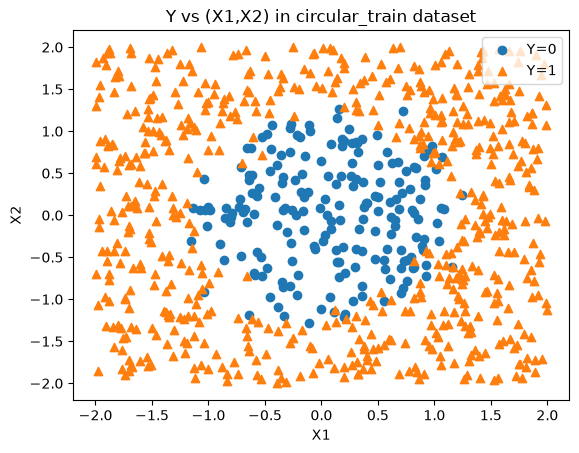

In [565]:
# Setting up the dataframes (note: I renamed "Outcome" in the csv to "Y")
circ_train = pd.read_csv("CSV_Files/circular_train.csv", names=["X1", "X2", "Y"], header=0)
circ_test = pd.read_csv("CSV_Files/circular_test.csv", names=["X1", "X2", "Y"], header=0)

# Plotting the datapoints with dots for Y=0 and triangles for Y=1
for y, marker in [(0, 'o'), (1, '^')]:
    subset = circ_train[circ_train['Y'] == y] # subset of dataframe for which Y=y
    plt.scatter(subset['X1'], subset['X2'], marker=marker, label=f'Y={y}')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title("Y vs (X1,X2) in circular_train dataset")
plt.legend()


#### (b) Fit ordinary logistic regression using (X1, X2). Display its fitted decision boundary. If the boundary does not cross the plotted range, report its equation.

Intercept: 1.1065303935096664
Coefficients: [-0.01672142  0.00030541]


c:\School\MAT3373\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


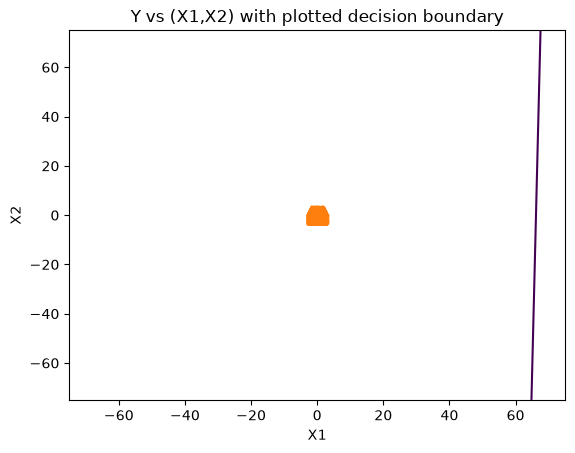

In [566]:
X_train = circ_train.drop(columns=["Y"]) # predictor variables (X1,X2)
y_train = circ_train["Y"] # target variable (variety)

# fitting model on training data
logreg = LogisticRegression()
logreg.fit(X_train, y_train)

# Plotting the datapoints with dots for Y=0 and triangles for Y=1
for y, marker in [(0, 'o'), (1, '^')]:
    subset = circ_train[circ_train['Y'] == y] # subset of dataframe for which Y=y
    plt.scatter(subset['X1'], subset['X2'], marker=marker, label=f'Y={y}')


# Creatimg a grid of points with which to plot the boundary 
x1 = np.linspace(-75, 75, 100) # Through testing, this is how far out I had to go to see the decision boundary!
x2 = np.linspace(-75, 75, 100)
xx1, xx2 = np.meshgrid(x1, x2)

# Predict probabilities across the grid
grid = np.column_stack([xx1.ravel(), xx2.ravel()])
probs = logreg.predict_proba(grid)[:, 1].reshape(xx1.shape)

# Plotting the decision boundary (i.e. where the probability is 50%)
plt.contour(xx1, xx2, probs, levels=[0.5])

plt.xlabel('X1')
plt.ylabel('X2')
plt.title("Y vs (X1,X2) with plotted decision boundary")

# Print decision boundary coefficients
print("Intercept:", logreg.intercept_[0])
print("Coefficients:", logreg.coef_[0])



Observations: the decision boundary does cross my plotted range, but only because I expanded the plotted range to an absurd degree, well beyond any of the values in the dataset. Indeed, under this model, every (X1,X2) pair in the original training dataset would be predicted to correspond to a 1, and the decision boundary would be well off-screen if we restricted the plot to the values in the original dataset.  

The equation of the decision boundary is: $1.1065303935096664 - 0.01672142X_1 + 0.00030541X_2 = 0$

---

#### (c) Define the new feature $R^2 = X_{1}^2 + X_{2}^2$, fit logistic regression using $R^2$ as its predictor, and display the fitted boundary in the original (X1, X2) coordinates.

Text(0.5, 1.0, 'Y vs (X1,X2) with plotted decision boundary')

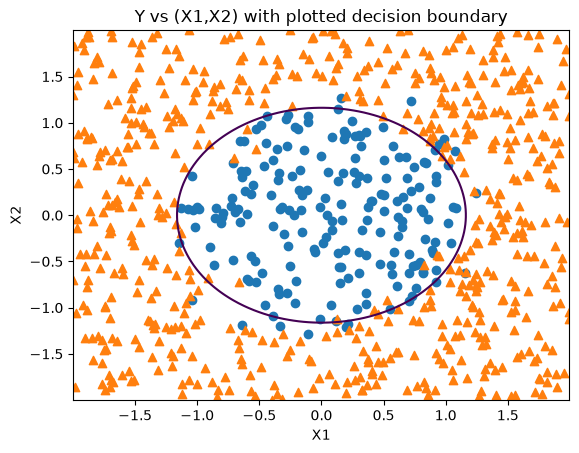

In [567]:
R2_train = pd.DataFrame({"R2": X_train["X1"] ** 2 + X_train["X2"] ** 2})
# fitting model on the new feature
logreg_R2 = LogisticRegression()
logreg_R2.fit(R2_train, y_train)

# Plotting the datapoints with dots for Y=0 and triangles for Y=1
for y, marker in [(0, 'o'), (1, '^')]:
    subset = circ_train[circ_train['Y'] == y] # subset of dataframe for which Y=y
    plt.scatter(subset['X1'], subset['X2'], marker=marker, label=f'Y={y}')

# Creatimg a grid of points with which to plot the boundary 
x1 = np.linspace(circ_train['X1'].min(), circ_train['X1'].max(), 100)
x2 = np.linspace(circ_train['X2'].min(), circ_train['X2'].max(), 100)
xx1, xx2 = np.meshgrid(x1, x2)

# Predict probabilities across the grid
grid_R2 = pd.DataFrame({"R2": xx1.ravel()**2 + xx2.ravel()**2}) # Converting each point in the grid to X1^2 + X2^2 so that our regression model can understand it
probs = logreg_R2.predict_proba(grid_R2)[:, 1].reshape(xx1.shape)

# Plotting the decision boundary (i.e. where the probability is 50%)
plt.contour(xx1, xx2, probs, levels=[0.5])

plt.xlabel('X1')
plt.ylabel('X2')
plt.title("Y vs (X1,X2) with plotted decision boundary")


#### (d) Fit a standardized KNN classifier. Choose k ∈ {1, 3, 5, . . . , 41} using five-fold stratified crossvalidation on the training data, with mean misclassification error as the criterion. Shuffle the folds and use random state=3373.

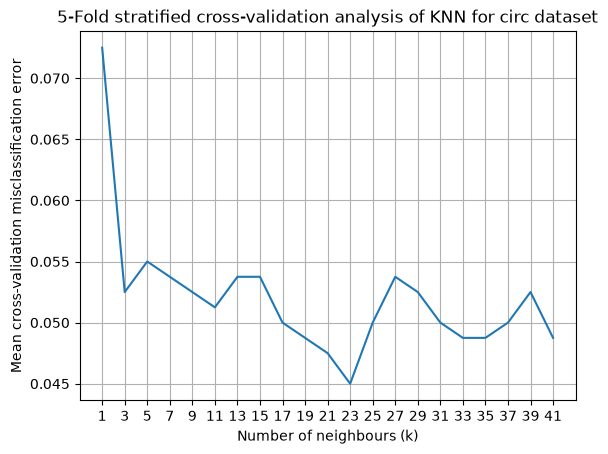

In [568]:
# setting up stratified cross-validation object
cv = StratifiedKFold(
    n_splits=5, # five folds
    shuffle=True,  # shuffle the folds
    random_state=3373 # fixed random state
)

# list to store mean cross-validation misclassification errors against k
cv_errors = []

# test k-values from 1 to 41 skipping even values
k_values = range(1, 42, 2) 

# For each k...
for k in k_values:
    # Standardized KNN classifier
    knn = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    # Calculate cross-validation accuracy for each fold using sklearn's cross_val_score()
    scores = cross_val_score(
        knn, # knn classifier for given k
        X_train, # predictor variables from training data
        y_train, # target variables from training data
        cv=cv, # cross-validation model
    )

    # convert accuracies to misclassification errors
    mean_error = np.mean(1 - scores)
    
    # append mean cross-validation misclassification error for size k to errors list
    cv_errors.append(mean_error) 

# plotting the results
plt.plot(k_values, cv_errors) # errors vs k-values
plt.xlabel("Number of neighbours (k)")
plt.ylabel("Mean cross-validation misclassification error")
plt.title("5-Fold stratified cross-validation analysis of KNN for circ dataset")
plt.xticks(k_values)
plt.grid(True)


From the plot, here k=23 is the optimal candidate given our constraints (odd numbers between 1 and 41). Now to fit the data for k=23:

In [569]:
k = 23 # choice of k based on cross-validation results

# Refit the classifier using all of the training data
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=k)
)
knn.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['X1','X2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


####  (e) Compare final test error for the three fitted rules. Also compare final test log loss for the two logistic-regression rules

In [570]:
X_test = circ_test.drop(columns=["Y"]) # predictor variables (X1,X2)
y_test = circ_test["Y"] # target variable (variety)
R2_test = pd.DataFrame({"R2": X_test["X1"] ** 2 + X_test["X2"] ** 2})

# Naive logistic regression test error:
y_pred = logreg.predict(X_test)
test_error = 1 - accuracy_score(y_test, y_pred)
print("Naive logistic regression test error:", test_error)

# R^2 logistic regression test error:
y_pred = logreg_R2.predict(R2_test)
test_error = 1 - accuracy_score(y_test, y_pred)
print("R^2 logistic regression test error:", test_error)

# KNN (after cross-validation) test error:
y_pred = knn.predict(X_test)
test_error = 1 - accuracy_score(y_test, y_pred)
print("KNN test error:", test_error)

print()

# Naive logistic regression log loss
probs_naive = logreg.predict_proba(X_test)[:, 1]
loss_naive = log_loss(y_test, probs_naive)
print("Naive logistic regression log loss:", loss_naive)

# R^2 logistic regression log loss
probs_R2 = logreg_R2.predict_proba(R2_test)[:, 1]
loss_R2 = log_loss(y_test, probs_R2)
print("R^2 logistic regression log loss:", loss_R2)


Naive logistic regression test error: 0.2676666666666667
R^2 logistic regression test error: 0.05233333333333334
KNN test error: 0.05566666666666664

Naive logistic regression log loss: 0.5821020118621717
R^2 logistic regression log loss: 0.12655681895427084


Among the three classifiers, the R^2 logistic regression showed the lowest test error, but KNN came quite close, suggesting either one is a viable option here. Crucially, naive logistic regression tested much worse than the other two options, suggesting that it is not a good choice of classifier for this problem.

Comparing the log loss of the two logistic regression models, the naive model again performed worse, indicating that it assigned relatively low probabilities to the true classifications of many observations / high probabilities to many incorrect classifications. This is consistent with what I observed earlier about the naive regression model learning to classify every datapoint in the training set as a 1 with reasonably high confidence, regardless of the datapoint's predictors. 

---

#### (f) Explain why the improvement after introducing R2 is usefully described as a change of representation. State one conclusion supported by this experiment and one broader conclusion that is not supported

A "change of representation" is a good name for this improvement as it involves representing the predictor variables in a new way in order to capture some hidden feature of the data (ideally a feature related to its true classification rule). One conclusion supported by this experiment is its potential effectiveness: by simply using the squared-distance of (X1,X2) from (0,0) rather than using X1 and X2 directly, we were able to train a much better logistic regression model without modifying the underlying algorithm at all. Something that is not supported is that this is always an effective solution, or that every transformation will be meaningful. In this case, a datapoint's distance from (0,0) seems to have been unusually consequential to its true classification, which is why this change of representation worked so well. 

---

## 4. Lying with Linear Regression
Throughout the question, use at least 20 distinct X-values. Every chosen X-value is paired with the observed value $Y=sin(X)$ which we will fit with the usual linear regression model.

#### (a) Find a collection of predictors X1, . . . , Xn for which the reported 99-percent confidence interval for the slope β1 is contained in (−∞, −0.95]. Display the points and report the estimated slope and confidence interval.

In [ ]:
n=10

# Idea: use only X-values immediately surrounding the value pi where sin is sloped most negatively
x_train = pd.DataFrame({"X": np.linspace(np.pi - 0.1, np.pi + 0.1, num=n)}) # generates n evenly-spaced points around pi
y_train = pd.DataFrame({"Y":np.sin(x_train["X"])})
points = x_train.join(y_train)

print(points)

# Fitting the model (using scipy for easier confidence intervals)
linreg = stats.linregress(x_train["X"], y_train["Y"]) 

# Calculating confidence interval bounds
t_crit = stats.t.ppf(0.995, n-2) # student's t-distribution for two-sided 99% test
moe = t_crit * linreg.stderr # margin of error
ci_lower = linreg.slope - moe
ci_upper = linreg.slope + moe

print()
print("Estimated slope:", linreg.slope)
print("99% CI lower bound:", ci_lower)
print("99% CI upper bound:", ci_upper)


          X         Y
0  3.041593  0.099833
1  3.063815  0.077699
2  3.086037  0.055527
3  3.108259  0.033327
4  3.130482  0.011111
5  3.152704 -0.011111
6  3.174926 -0.033327
7  3.197148 -0.055527
8  3.219370 -0.077699
9  3.241593 -0.099833

Estimated slope: [-0.99879475]
99% CI lower bound: [-0.9993918]
99% CI upper bound: [-0.9981977]


#### (b) Find a collection of predictors X1, . . . , Xn for which the reported 99-percent confidence interval for the slope β1 is contained in [0.95,∞). Display the points and report the estimated slope and confidence interval.

In [572]:
n=10

# Exact same idea just around 0 rather than pi, where sin is most positively sloped
x_train = pd.DataFrame({"X": np.linspace(-0.1, 0.1, num=n)}) # generates n evenly-spaced points around 0
y_train = pd.DataFrame({"Y":np.sin(x_train["X"])})
points = x_train.join(y_train)

print(points)

# Fitting the model (using scipy for easier confidence intervals)
linreg = stats.linregress(x_train["X"], y_train["Y"]) 

# Calculating confidence interval bounds
t_crit = stats.t.ppf(0.995, n-2) # student's t-distribution for two-sided 99% test
moe = t_crit * linreg.stderr # margin of error
ci_lower = linreg.slope - moe
ci_upper = linreg.slope + moe

print()
print("Estimated slope:", linreg.slope)
print("99% CI lower bound:", ci_lower)
print("99% CI upper bound:", ci_upper)

          X         Y
0 -0.100000 -0.099833
1 -0.077778 -0.077699
2 -0.055556 -0.055527
3 -0.033333 -0.033327
4 -0.011111 -0.011111
5  0.011111  0.011111
6  0.033333  0.033327
7  0.055556  0.055527
8  0.077778  0.077699
9  0.100000  0.099833

Estimated slope: 0.9987947508158651
99% CI lower bound: 0.9981976986518187
99% CI upper bound: 0.9993918029799115


#### (c) Would part (b) be possible if [0.95, ∞) were replaced by [100, ∞)? Explain why or why not.

No. The key to understanding why is recognizing that cos, the derivative of sin, is bounded between -1 and 1. 

This fact can be used to show that the slope of the secant line connecting any two points on a sin curve must also be bounded between -1 and 1 (formalized with the mean value theorem), and then showing that the slope estimator used in linear regression can be expressed as a weighted average of the slopes between every pair of observations (each one a secant line on the sin curve). Now since each individual term in this weighted average cannot exceed 1, the slope estimator itself cannot exceed 1, therefore the confidence interval (which must contain the slope estimator) cannot be entirely above 1.

---

## 5 Simulation Study: Post-Selection Inference
Generate m = 80 predictors and one response for n = 100 observations according to:
rng = np.random.default_rng(3373)  
X = rng.normal(size=(100, 80))  
y = rng.normal(size=100)  
There is no relationship between any predictor and the response.

In [ ]:
rng = np.random.default_rng(3373)  
X = rng.normal(size=(100, 80))  
y = rng.normal(size=100)  